# Matplotlib基础

画图不是装饰。训练的时候 loss 曲线抖不抖、验证集是不是早就开始往上翘、两类样本能不能分开，这些看一张图比看十个数字快得多。

这一节把常用的几种图过一遍，目标是**看到需求能照着改出来**，不追求画得好看。真要做报告再去调配色和字号。

## 1. 两种写法

`plt.plot(...)` 这种叫 pyplot 状态机写法，短，但画子图的时候很容易搞不清在往哪张图上画。另一种是面向对象写法：

```python
fig, ax = plt.subplots()   # fig 是整张画布，ax 是一个坐标系
ax.plot(x, y)              # 所有东西往 ax 上加
```

后面统一用第二种。注意 `ax`（Axes）是一张图，`axis` 才是坐标轴，中文都翻成轴，看文档很容易看混。

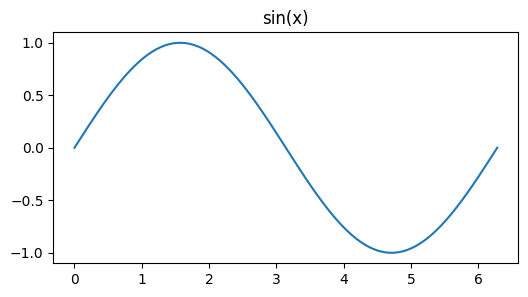

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 2 * np.pi, 100)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, np.sin(x))
ax.set_title("sin(x)")
plt.show()

`figsize` 是英寸，`(6, 3)` 大约是 600×300 像素（默认 dpi=100）。图太扁或者太方，先调这个。

## 2. 折线图

`ax.plot` 的参数很多，常用的：

| 参数 | 作用 | 例子 |
|---|---|---|
| `color` | 颜色 | `"tab:blue"`、`"r"`、`"#ff8800"` |
| `linestyle` | 线型 | `"-"` 实线、`"--"` 虚线、`":"` 点线 |
| `linewidth` | 线宽 | `2` |
| `marker` | 数据点标记 | `"o"` 圆、`"s"` 方块、`"^"` 三角 |
| `markersize` / `ms` | 标记大小 | `3` |
| `markevery` | 每隔几个点画一个标记 | `10` |
| `alpha` | 透明度 0~1 | `0.6` |
| `label` | 图例名，配合 `legend()` | `"sin"` |

也可以把颜色、线型、标记拼成一个字符串：`"r--o"`。

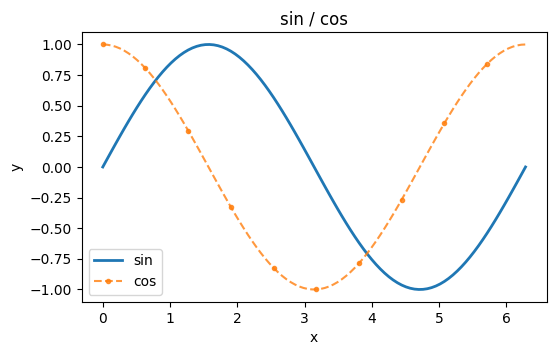

In [2]:
fig, ax = plt.subplots(figsize=(6, 3.5))

ax.plot(x, np.sin(x), color="tab:blue", linewidth=2, label="sin")
ax.plot(x, np.cos(x), color="tab:orange", linestyle="--",
        marker="o", markersize=3, markevery=10, alpha=0.8, label="cos")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("sin / cos")
ax.legend()
plt.show()

数据点密的时候千万别每个点都画 marker，会糊成一团，用 `markevery` 隔几个画一个。多条线放一起记得给 `label` 再调 `legend()`，不然图例是空的。

## 3. 中文和负号

这两行几乎每个 notebook 开头都要写：

```python
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
```

不设的话，标题里的中文会变成一个一个方框（缺字体的默认字体里没有汉字），负号也会变成方块。`Arial Unicode MS` 是 macOS 自带的，Windows 上一般写 `"SimHei"`（黑体）或 `"Microsoft YaHei"`。用 `font_manager` 可以查本机有什么字体。

`rcParams` 是全局设置，对当前内核里之后画的所有图生效。换了新 notebook 要重新写一遍，不会自动继承。

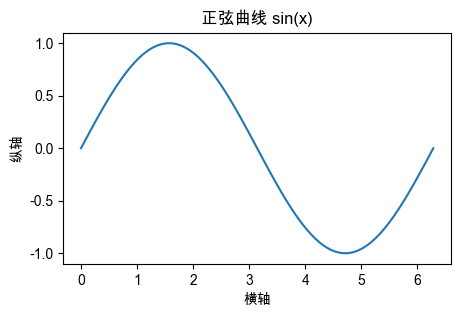

In [3]:
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(x, np.sin(x))
ax.set_title("正弦曲线 sin(x)")
ax.set_xlabel("横轴")
ax.set_ylabel("纵轴")
plt.show()

> seaborn 的 `set_theme()` 会把 `font.sans-serif` 重置掉，所以如果用 seaborn，要么把字体作为参数传进去，要么在它之后再设一次 `rcParams`。

## 4. 标题、坐标轴、图例、网格

| 方法 | 作用 |
|---|---|
| `ax.set_title("...", fontsize=14)` | 标题 |
| `ax.set_xlabel` / `set_ylabel` | 轴标签 |
| `ax.set_xlim(a, b)` / `set_ylim` | 轴范围 |
| `ax.set_xticks([...])` / `set_xticklabels([...])` | 指定刻度位置 / 文字 |
| `ax.tick_params(labelsize=9, rotation=45)` | 刻度字号、旋转 |
| `ax.legend(loc="upper right")` | 图例 |
| `ax.grid(alpha=0.3, linestyle="--")` | 网格 |
| `ax.axhline(y)` / `ax.axvline(x)` | 水平 / 竖直参考线 |
| `ax.annotate("文字", xy=(x, y), xytext=(...))` | 带箭头的标注 |

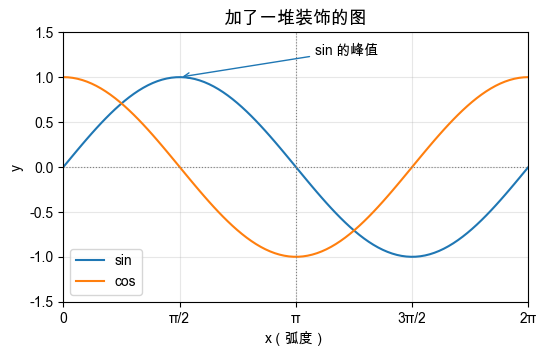

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))

ax.plot(x, np.sin(x), label="sin")
ax.plot(x, np.cos(x), label="cos")

ax.set_title("加了一堆装饰的图", fontsize=13)
ax.set_xlabel("x（弧度）")
ax.set_ylabel("y")
ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
ax.set_xticklabels(["0", "π/2", "π", "3π/2", "2π"])

ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
ax.axvline(np.pi, color="gray", linewidth=0.8, linestyle=":")

ax.annotate("sin 的峰值", xy=(np.pi / 2, 1), xytext=(3.4, 1.25),
            arrowprops={"arrowstyle": "->", "color": "tab:blue"})

ax.grid(alpha=0.3)
ax.legend(loc="lower left")
plt.show()

`legend` 的 `loc` 也接受字符串：`"upper right"`、`"lower left"`、`"best"`（默认，让它自己挑不挡线的地方）。

`annotate` 的 `arrowprops` 要传字典。这个参数文档写得比较绕，我一般直接抄现成的改坐标。

## 5. 散点图

散点图用来看两个特征的关系，以及分类任务里两类样本能不能分开。

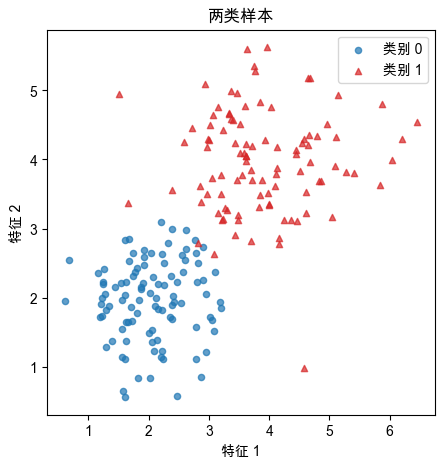

In [5]:
rng = np.random.default_rng(0)

x1, y1 = rng.normal(2, 0.6, 100), rng.normal(2, 0.6, 100)
x2, y2 = rng.normal(4, 0.8, 100), rng.normal(4, 0.8, 100)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(x1, y1, s=20, alpha=0.7, label="类别 0")
ax.scatter(x2, y2, s=20, alpha=0.7, c="tab:red", marker="^", label="类别 1")
ax.set_xlabel("特征 1")
ax.set_ylabel("特征 2")
ax.set_title("两类样本")
ax.legend()
plt.show()

参数里 `s` 是点的**面积**（不是半径），点多了或者太挤就调小，再配合 `alpha` 看密度。

如果 `c` 给一个数值数组，再给 `cmap`，就能按数值上色，旁边加个 `colorbar`：

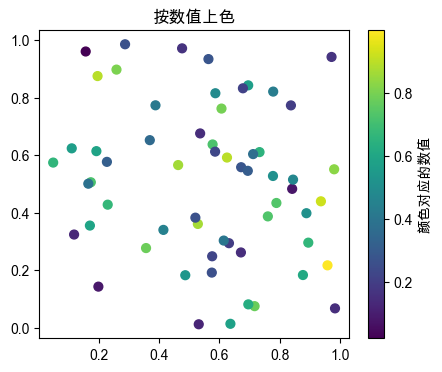

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
sc = ax.scatter(rng.random(60), rng.random(60), c=rng.random(60),
                cmap="viridis", s=40)
fig.colorbar(sc, ax=ax, label="颜色对应的数值")
ax.set_title("按数值上色")
plt.show()

## 6. 柱状图和直方图

两个图长得像，用途完全不同：

- `bar`：横轴是**类别**，柱子高度是某个统计量（各班平均分、各模型准确率）；
- `hist`：横轴是**连续值的区间**，柱子高度是落在这个区间里的个数（成绩分布、特征分布）。

拿 bar 画分布或者拿 hist 画类别，都是把数据先分错了组。

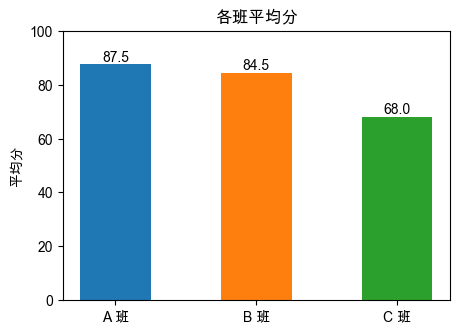

In [7]:
classes = ["A 班", "B 班", "C 班"]
avg = [87.5, 84.5, 68.0]

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(classes, avg, width=0.5,
              color=["tab:blue", "tab:orange", "tab:green"])
ax.bar_label(bars, fmt="%.1f")
ax.set_ylim(0, 100)
ax.set_ylabel("平均分")
ax.set_title("各班平均分")
plt.show()

分组柱状图（同一类别下比较两项）要自己算横坐标偏移，没有现成参数：

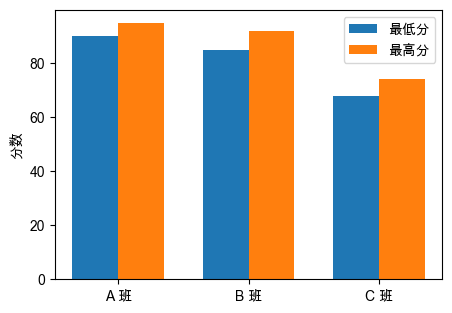

In [8]:
pos = np.arange(len(classes))
w = 0.35

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(pos - w / 2, [90, 85, 68], width=w, label="最低分")
ax.bar(pos + w / 2, [95, 92, 74], width=w, label="最高分")
ax.set_xticks(pos)
ax.set_xticklabels(classes)
ax.set_ylabel("分数")
ax.legend()
plt.show()

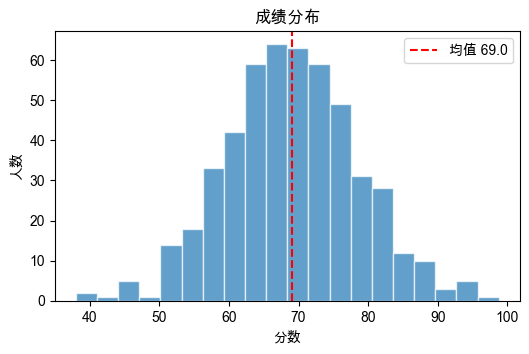

In [9]:
data = rng.normal(70, 10, 500)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(data, bins=20, color="tab:blue", alpha=0.7, edgecolor="white")
ax.axvline(data.mean(), color="red", linestyle="--",
           label=f"均值 {data.mean():.1f}")
ax.set_xlabel("分数")
ax.set_ylabel("人数")
ax.set_title("成绩分布")
ax.legend()
plt.show()

`bins` 给少了看不出形状，给多了全是毛刺，20~50 之间多试两次就有感觉了。`edgecolor="white"` 让柱子之间有条白缝，比默认好看。

`density=True` 换成概率密度（纵轴不再是人数），想和正态分布的理论曲线叠在一起时用。

## 7. 子图

`plt.subplots(2, 2)` 返回 `(fig, axs)`，`axs` 是一个 2×2 的数组，用 `axs[0, 1]` 这种下标取。只有一个子图时 `axs` 不是数组，直接就是那个 `ax`。

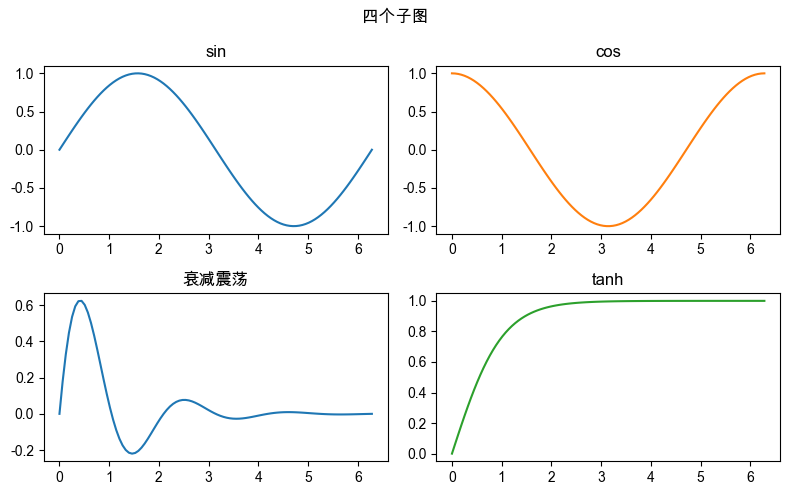

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(8, 5))

axs[0, 0].plot(x, np.sin(x))
axs[0, 0].set_title("sin")

axs[0, 1].plot(x, np.cos(x), color="tab:orange")
axs[0, 1].set_title("cos")

axs[1, 0].plot(x, np.exp(-x) * np.sin(3 * x))
axs[1, 0].set_title("衰减震荡")

axs[1, 1].plot(x, np.tanh(x), color="tab:green")
axs[1, 1].set_title("tanh")

fig.suptitle("四个子图")
fig.tight_layout()      # 不写的话标题容易互相压住
plt.show()

`tight_layout()` 基本是必写的，不然图上文字容易糊在一起。新版也可以用 `fig, axs = plt.subplots(..., layout="constrained")`，效果差不多。

子图多、每个图都要设同样的东西时，用 `for ax in axs.flat:` 循环比一个个写省事。

## 8. 保存图片

`savefig` 要**在 `show()` 之前**调用。`show()` 之后 figure 会被清掉，再存就是一张空白图，这个坑很常见。

已保存 sine_demo.png


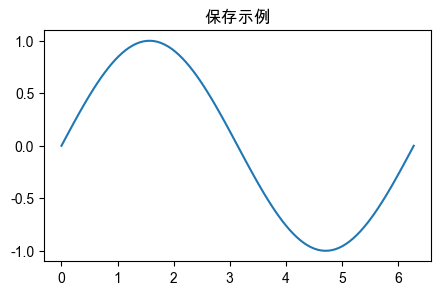

In [11]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(x, np.sin(x))
ax.set_title("保存示例")

fig.savefig("sine_demo.png", dpi=150, bbox_inches="tight")
print("已保存 sine_demo.png")
plt.show()

常用参数：

- `dpi`：清晰度，屏幕上 100 够用，放报告 / 论文里给 300；
- `bbox_inches="tight"`：把周围多余的白边裁掉，不然插到文档里留白很难看；
- 格式看后缀：`.png` 位图，`.pdf` / `.svg` 矢量，论文里放大不糊。

存好的图直接嵌进 markdown 就能看：

![sine_demo.png](sine_demo.png)

## 9. 常用参数速查

| 类别 | 常用值 |
|---|---|
| 颜色简写 | `"b"` 蓝、`"g"` 绿、`"r"` 红、`"c"` 青、`"m"` 品红、`"y"` 黄、`"k"` 黑、`"w"` 白 |
| 调色板颜色 | `"tab:blue"`、`"tab:orange"`、`"tab:green"`，比简写好看 |
| 十六进制 | `"#1f77b4"`，取色器里复制 |
| 线型 | `"-"` 实线、`"--"` 虚线、`"-."` 点划线、`":"` 点线 |
| 标记 | `"o"` 圆、`"s"` 方、`"^"` 上三角、`"*"` 星、`"x"` 叉 |
| colormap | `"viridis"`（默认）、`"coolwarm"`（正负对比）、`"Blues"`（单色深浅） |

选 colormap 的一个原则：连续数值用 `viridis` 这类感知均匀的；表示正负、好坏用 `coolwarm` 这类发散型；画混淆矩阵用 `Blues` 就行。

## 10. ML 里常见的图

**训练曲线**：看收敛和过拟合，调 early stopping 全靠它。

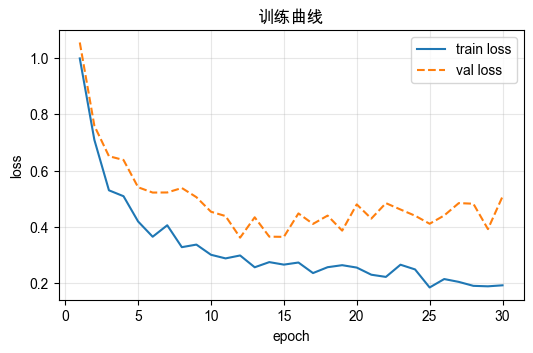

In [12]:
epochs = np.arange(1, 31)
train_loss = 1.0 / epochs ** 0.5 + rng.normal(0, 0.02, 30)
val_loss = 1.0 / epochs ** 0.45 + rng.normal(0, 0.05, 30) + epochs * 0.008

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(epochs, train_loss, label="train loss")
ax.plot(epochs, val_loss, linestyle="--", label="val loss")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_title("训练曲线")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

读法：两条都在降说明还没收敛；train 一直降、val 开始往上翘，就是过拟合开始的位置，early stopping 就停在那附近。

**决策边界**：`contourf` 把整个平面按预测结果涂色，再把样本点叠上去。

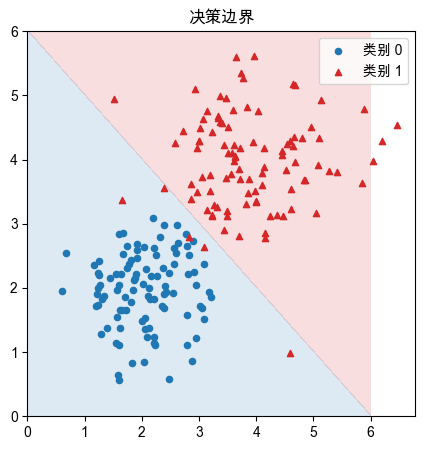

In [13]:
xx, yy = np.meshgrid(np.linspace(0, 6, 200), np.linspace(0, 6, 200))

# 先拿 x + y = 6 这条直线冒充模型
Z = (xx + yy) > 6

fig, ax = plt.subplots(figsize=(5, 5))
ax.contourf(xx, yy, Z.astype(int), levels=[-0.5, 0.5, 1.5],
            colors=["tab:blue", "tab:red"], alpha=0.15)
ax.scatter(x1, y1, s=20, label="类别 0")
ax.scatter(x2, y2, s=20, c="tab:red", marker="^", label="类别 1")
ax.set_title("决策边界")
ax.legend()
plt.show()

**混淆矩阵**：本质是画一张二维表格，用 `imshow` 加手动写数字。

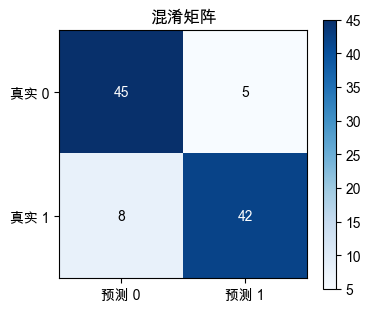

In [14]:
cm = np.array([[45, 5], [8, 42]])

fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["预测 0", "预测 1"])
ax.set_yticklabels(["真实 0", "真实 1"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

ax.set_title("混淆矩阵")
fig.colorbar(im, ax=ax)
plt.show()

以后用 sklearn 的话，`ConfusionMatrixDisplay.from_predictions(y_true, y_pred)` 一行就能画，不用自己写。但这段手写的能看清 `imshow` 的坐标是先行后列，`text(j, i)` 是 (x, y) 顺序。

## 11. 顺带提一下 seaborn

matplotlib 什么都能画，但画统计图要写不少代码。seaborn 建在它上面，一行出图，默认样式也好看。

两个最常用的：看单列分布用 `histplot`，看特征之间的相关性用 `heatmap`。

      a     b     c
a  1.00  0.02  0.04
b  0.02  1.00  0.05
c  0.04  0.05  1.00


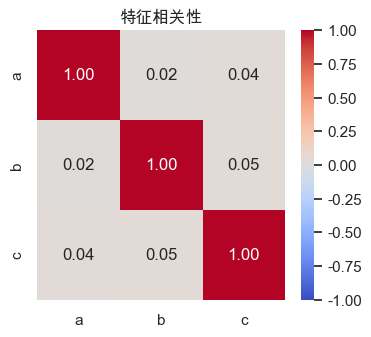

In [15]:
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", font="Arial Unicode MS",
              rc={"axes.unicode_minus": False})

df = pd.DataFrame(rng.normal(size=(200, 3)), columns=["a", "b", "c"])
print(df.corr().round(2))

fig, ax = plt.subplots(figsize=(4, 3.5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("特征相关性")
plt.show()

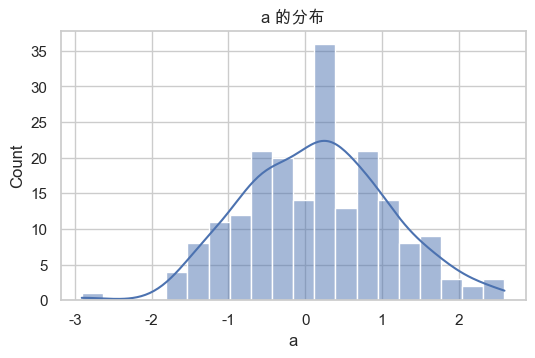

In [16]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(df["a"], bins=20, kde=True, ax=ax)
ax.set_title("a 的分布")
plt.show()

`kde=True` 会叠一条核密度曲线，比纯直方图更容易看出形状。不过数据量少的时候曲线会很怪，那时候就关掉。